# Продление данных до 2010 года: как учесть смену методики цены газа

**Зачем этот ноутбук.** Основной анализ начинается в апреле 2015 года, потому что только с этого месяца цена газа Европы в Pink Sheet считается по биржевому хабу TTF. До апреля 2015 года в этой колонке стоит другой показатель: средняя цена импорта газа на границе, которая в основном определялась долгосрочными контрактами с привязкой к нефти, а с 2010 года включала и спотовую цену Великобритании. Здесь мы проверяем, можно ли продлить данные до января 2010 года и как при этом учесть смену методики.

**Что проверяем.**
1. Как выглядят два показателя цены газа на графике.
2. Меняется ли связь цены карбамида с ценой газа в апреле 2015 года (тест Чоу на структурный сдвиг).
3. Какой k получается до и после апреля 2015 года и остаётся ли надбавка стационарной на длинной выборке.
4. Становится ли прогноз точнее, если обучать модель на данных с 2010 года, и нужен ли для этого флаг смены методики.

**Периоды.** Длинный трейн охватывает период с января 2010 по сентябрь 2023 года (165 месяцев), обычный трейн охватывает период с апреля 2015 по сентябрь 2023 года (102 месяца). Тест с октября 2023 по сентябрь 2026 года мы не трогаем.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.stattools import adfuller
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from src.models.backtest import make_table_full, rolling_backtest, score

# загружаем Pink Sheet так же, как в основном ноутбуке
raw = pd.read_excel("../data/raw/CMO-Historical-Data-Monthly.xlsx", sheet_name="Monthly Prices", header=None)
header_row = raw.index[raw.astype(str).apply(lambda r: r.str.strip().str.startswith("Urea").any(), axis=1)][0]
columns = raw.iloc[header_row].fillna("").astype(str).str.strip().str.replace(r"\s*\*+$", "", regex=True)
body = raw.iloc[header_row + 2:].copy()
body.columns = columns
body = body[body.iloc[:, 0].astype(str).str.match(r"^\d{4}M\d{2}$")]
body.index = pd.to_datetime(body.iloc[:, 0].str.replace("M", "-") + "-01")
names = {
    "Crude oil, Brent": "brent", "Coal, Australian": "coal_aus", "Coal, South African": "coal_safr",
    "Natural gas, US": "gas_us", "Natural gas, Europe": "gas_europe", "Liquefied natural gas, Japan": "lng_japan",
    "Urea": "urea_price", "DAP": "dap", "TSP": "tsp", "Phosphate rock": "phosphate_rock", "Potassium chloride": "potash",
    "Maize": "maize", "Wheat, US HRW": "wheat", "Soybeans": "soybeans", "Rice, Thai 5%": "rice",
    "Sugar, world": "sugar", "Palm oil": "palm_oil", "Copper": "copper", "Iron ore, cfr spot": "iron_ore", "Aluminum": "aluminum",
}
full = pd.DataFrame({new: pd.to_numeric(body[old].replace("…", np.nan), errors="coerce") for old, new in names.items()})

prices = full.loc["2010-01":].copy()                  # длинная выборка с января 2010
BREAK = pd.Timestamp("2015-04-01")                     # смена методики цены газа Европы
train = prices.loc[:"2023-09"]                         # длинный трейн
pre = train.loc[:"2015-03"]                            # до смены методики
post = train.loc["2015-04":]                           # после смены методики (обычный трейн)
print("Пропусков с 2010 года:", int(prices.isna().sum().sum()))
print("Длинный трейн:", len(train), "мес.; до апреля 2015:", len(pre), "мес.; после:", len(post), "мес.")

Пропусков с 2010 года: 0
Длинный трейн: 165 мес.; до апреля 2015: 63 мес.; после: 102 мес.


## 1. Два показателя цены газа Европы на графике
Мы показываем цену газа Европы вместе с ценой нефти Brent, пересчитанной в доллары за миллион БТЕ (баррель нефти содержит около 5,8 миллиона БТЕ), и ценой газа США. Пунктир отмечает апрель 2015 года.

Стандартное отклонение месячного изменения цены газа Европы:
  до апреля 2015 года: 4.8 %
  с апреля 2015 года по сентябрь 2023 года: 17.8 %


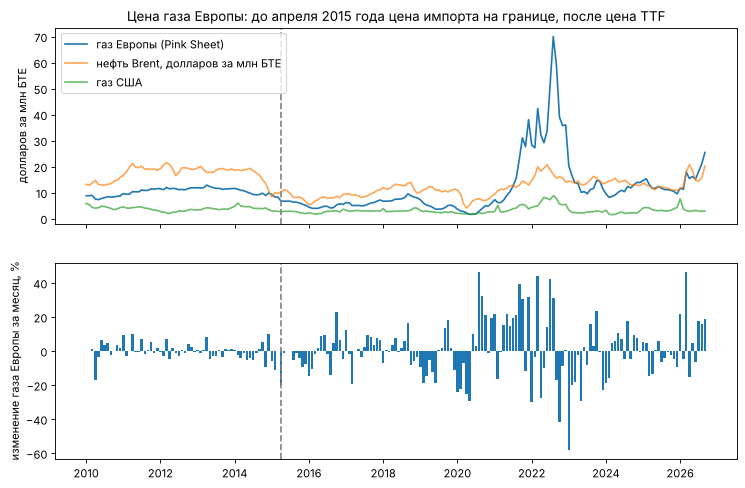

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(prices.index, prices["gas_europe"], label="газ Европы (Pink Sheet)")
axes[0].plot(prices.index, prices["brent"] / 5.8, label="нефть Brent, долларов за млн БТЕ", alpha=0.7)
axes[0].plot(prices.index, prices["gas_us"], label="газ США", alpha=0.7)
axes[0].set_ylabel("долларов за млн БТЕ")
axes[0].legend(loc="upper left")
change = np.log(prices["gas_europe"]).diff() * 100
axes[1].bar(change.index, change, width=25)
axes[1].set_ylabel("изменение газа Европы за месяц, %")
for ax in axes:
    ax.axvline(BREAK, color="gray", linestyle="--")
axes[0].set_title("Цена газа Европы: до апреля 2015 года цена импорта на границе, после цена TTF")
plt.show()

print("Стандартное отклонение месячного изменения цены газа Европы:")
print("  до апреля 2015 года:", round(change.loc[:"2015-03"].std(), 1), "%")
print("  с апреля 2015 года по сентябрь 2023 года:", round(change.loc["2015-04":"2023-09"].std(), 1), "%")

**Главный результат: до апреля 2015 года цена газа Европы почти не колебалась от месяца к месяцу и шла вслед за нефтью, поэтому это другой по смыслу ряд, чем TTF.**

До апреля 2015 года цена газа Европы плавно повторяет движение нефти с запаздыванием, потому что цена долгосрочных контрактов была привязана к нефти. Месячные изменения этой цены почти в четыре раза меньше по разбросу, чем у TTF. После апреля 2015 года цена газа стала биржевой и начала резко реагировать на баланс спроса и предложения газа в Европе. Поэтому склеивать два ряда как один показатель нельзя.

## 2. Тест Чоу: меняется ли связь цены карбамида с ценой газа в апреле 2015 года
Тест Чоу сравнивает одну регрессию на всём длинном трейне с двумя отдельными регрессиями до и после апреля 2015 года. Если две отдельные регрессии описывают данные заметно лучше, связь изменилась, то есть произошёл структурный сдвиг. Нулевая гипотеза теста состоит в том, что сдвига нет; если p меньше 0,05, сдвиг есть.

Мы проверяем две связи: уровень цены карбамида против уровня цены газа и изменение цены карбамида в следующем месяце против изменения цены газа в текущем месяце.

In [3]:
def ssr(x, y):
    # сумма квадратов остатков линейной регрессии y на x со свободным членом
    X = np.column_stack([np.ones(len(x)), x])
    b, *_ = np.linalg.lstsq(X, y, rcond=None)
    e = y - X @ b
    return e @ e

def chow_test(x, y, break_date):
    # F-статистика Чоу и p-значение для сдвига в дату break_date
    before = x.index < break_date
    s_all = ssr(x.values, y.values)
    s_1 = ssr(x.values[before], y.values[before])
    s_2 = ssr(x.values[~before], y.values[~before])
    k, n = 2, len(x)
    f_stat = ((s_all - s_1 - s_2) / k) / ((s_1 + s_2) / (n - 2 * k))
    return round(f_stat, 2), round(1 - stats.f.cdf(f_stat, k, n - 2 * k), 3)

levels = chow_test(train["gas_europe"], train["urea_price"], BREAK)
gas_change = np.log(train["gas_europe"]).diff()
urea_next = np.log(train["urea_price"]).diff().shift(-1)
pair = pd.concat([gas_change, urea_next], axis=1).dropna()
changes = chow_test(pair.iloc[:, 0], pair.iloc[:, 1], BREAK)

print("Уровни (цена карбамида против цены газа):   F =", levels[0], " p =", levels[1])
print("Изменения (газ сейчас, карбамид через месяц): F =", changes[0], " p =", changes[1])

rows = []
for name, part in [("до апреля 2015", pre), ("с апреля 2015", post)]:
    g = np.log(part["gas_europe"]).diff()
    u = np.log(part["urea_price"]).diff().shift(-1)
    ok = g.notna() & u.notna()
    fit = stats.linregress(g[ok], u[ok])
    rows.append({"период": name, "наклон по изменениям": round(fit.slope, 2),
                 "± 95%": round(1.96 * fit.stderr, 2), "корреляция": round(fit.rvalue, 2)})
pd.DataFrame(rows)

Уровни (цена карбамида против цены газа):   F = 4.32  p = 0.015
Изменения (газ сейчас, карбамид через месяц): F = 0.09  p = 0.918


,период,наклон по изменениям,± 95%,корреляция
0,до апреля 2015,0.14,0.72,0.05
1,с апреля 2015,0.25,0.12,0.38


**Главный результат: в уровнях связь цены карбамида с ценой газа в апреле 2015 года меняется (p = 0,015), а в изменениях тест сдвиг не находит, но только потому, что до 2015 года изменение цены газа почти ничего не объясняет.**

- **Уровни.** Тест Чоу показывает значимый сдвиг: наклон цены карбамида по цене газа до апреля 2015 года и после него разный. Оговорка: в уровнях остатки регрессии сильно зависят друг от друга во времени, поэтому значимость теста может быть завышена.
- **Изменения.** Тест сдвиг не находит (p около 0,9). Однако до апреля 2015 года корреляция изменения цены газа с изменением цены карбамида через месяц равна всего 0,05, а доверительный интервал наклона очень широкий, потому что цена газа почти не менялась от месяца к месяцу. Тест просто не может отличить слабую связь от сильной на таком малоподвижном ряде. После апреля 2015 года связь значима (корреляция 0,38).

Вывод: до 2015 года цена газа Европы как признак почти бесполезна для прогноза, а её уровень нельзя использовать с тем же k, что после 2015 года.

## 3. Коэффициент k до и после апреля 2015 года и стационарность надбавки на длинной выборке
Мы оцениваем k отдельно до и после смены методики и проверяем тестом ADF три варианта надбавки:
1. надбавка с k = 12 на обычном трейне с апреля 2015 года (как в основном ноутбуке);
2. надбавка с k = 12 на длинном трейне с января 2010 года;
3. надбавка с двумя разными k: свой k до апреля 2015 года и k = 12 после.

Чем более отрицательна статистика t, тем увереннее надбавка возвращается к своему нормальному уровню.

            период  месяцев  k (наклон)  ± 95%   R²
    до апреля 2015       63        27.9   11.2 0.28
     с апреля 2015      102        12.0    1.5 0.70
весь длинный трейн      165        12.1    1.4 0.65

                             вариант надбавки  ADF t  порог 5% стационарна
                        k = 12, с апреля 2015  -3.50     -2.89          да
                        k = 12, с января 2010  -4.15     -2.88          да
два k (27.9 до 2015, 12 после), с января 2010  -3.13     -2.88          да


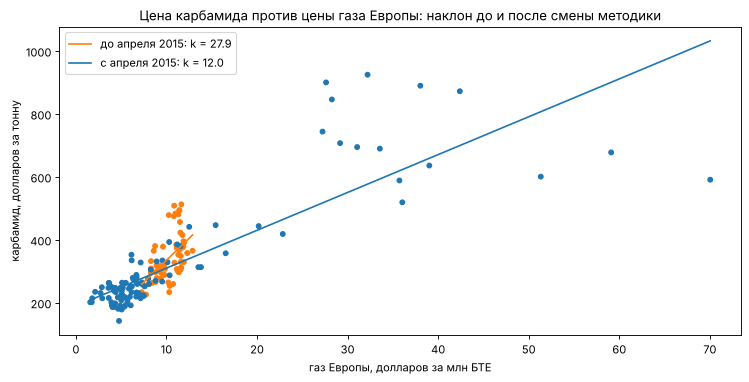

In [4]:
rows = []
for name, part in [("до апреля 2015", pre), ("с апреля 2015", post), ("весь длинный трейн", train)]:
    fit = stats.linregress(part["gas_europe"], part["urea_price"])
    rows.append({"период": name, "месяцев": len(part), "k (наклон)": round(fit.slope, 1),
                 "± 95%": round(1.96 * fit.stderr, 1), "R²": round(fit.rvalue ** 2, 2)})
k_table = pd.DataFrame(rows)
print(k_table.to_string(index=False))
k_pre = k_table.loc[0, "k (наклон)"]

variants = {
    "k = 12, с апреля 2015": post["urea_price"] - 12 * post["gas_europe"],
    "k = 12, с января 2010": train["urea_price"] - 12 * train["gas_europe"],
    f"два k ({k_pre} до 2015, 12 после), с января 2010":
        train["urea_price"] - np.where(train.index < BREAK, k_pre, 12) * train["gas_europe"],
}
rows = []
for name, markup in variants.items():
    result = adfuller(markup, autolag="AIC")
    rows.append({"вариант надбавки": name, "ADF t": round(result[0], 2), "порог 5%": round(result[4]["5%"], 2),
                 "стационарна": "да" if result[0] < result[4]["5%"] else "нет"})
print()
print(pd.DataFrame(rows).to_string(index=False))

fig, ax = plt.subplots(figsize=(11, 5))
colors = np.where(train.index < BREAK, "tab:orange", "tab:blue")
ax.scatter(train["gas_europe"], train["urea_price"], c=colors, s=18)
for part, color, label in [(pre, "tab:orange", "до апреля 2015"), (post, "tab:blue", "с апреля 2015")]:
    fit = stats.linregress(part["gas_europe"], part["urea_price"])
    x = np.sort(part["gas_europe"].values)
    ax.plot(x, fit.intercept + fit.slope * x, color=color, label=f"{label}: k = {fit.slope:.1f}")
ax.set_xlabel("газ Европы, долларов за млн БТЕ")
ax.set_ylabel("карбамид, долларов за тонну")
ax.set_title("Цена карбамида против цены газа Европы: наклон до и после смены методики")
ax.legend()
plt.show()

**Главный результат: до апреля 2015 года k оценивается очень неточно (около 28 ± 11), поэтому для надбавки на длинной выборке лучше использовать один k = 12, и тогда надбавка остаётся стационарной.**

- До апреля 2015 года наклон цены карбамида по цене газа составляет около 28, но доверительный интервал очень широкий (± 11), а цена газа объясняет только 28% колебаний цены карбамида. После апреля 2015 года k = 12,0 ± 1,5, и цена газа объясняет 70% колебаний. Значит, k до 2015 года является ненадёжной оценкой.
- Надбавка с k = 12 на длинном трейне с 2010 года стационарна, причём даже увереннее, чем на обычном трейне (t = −4,15 против −3,50). Причина в том, что в период с 2010 по 2015 год цены были спокойными и надбавка держалась около своего среднего уровня.
- Надбавка с двумя разными k проходит только обычный порог (t = −3,13 при пороге −2,88). Строгий порог для k, оценённого по тем же данным (около −3,37), она уже не проходит. Значит, второй k не улучшает надбавку, потому что сам оценён неточно.

Оговорка: до 2015 года газовая составляющая надбавки посчитана по цене импорта на границе, а не по TTF. Поэтому надбавка до и после 2015 года по смыслу немного разная, и для объяснения цены (разложения на газ и надбавку) мы, как и раньше, используем период с апреля 2015 года.

## 4. Помогает ли длинная история прогнозу и нужен ли флаг смены методики
Мы прогнозируем изменение цены карбамида через 1 и 3 месяца моделью Ridge, как в ноутбуке 04_strict_validation. Целевая переменная (изменение цены) не требует k, поэтому смена методики газа её почти не затрагивает. Признаки одинаковые во всех вариантах: месячные изменения цен газа Европы, DAP, угля Австралии, алюминия, нефти Brent, газа США и меди.

Сравниваем три варианта обучения на одних и тех же месяцах валидации (с октября 2020 по сентябрь 2023 года), окно обучения расширяющееся:
1. обучение с апреля 2015 года (как сейчас);
2. обучение с января 2010 года без флага;
3. обучение с января 2010 года с флагом gas_oil_indexed (1 до апреля 2015 года) и признаком «изменение цены газа × флаг», который позволяет модели учитывать газ отдельно до смены методики и после неё.

Число в таблице показывает отношение ошибки модели (MSE) к ошибке наивного прогноза. Если отношение меньше 1, модель лучше наивного прогноза.

Отношение MSE модели к MSE наивного прогноза (меньше 1: модель лучше):
 горизонт, мес.                 обучение  все  без кризиса  кризис
              1            с апреля 2015 0.91         0.74    0.94
              1 с января 2010, без флага 0.82         0.53    0.86
              1  с января 2010, с флагом 0.83         0.54    0.87
              3            с апреля 2015 1.44         0.98    1.49
              3 с января 2010, без флага 1.12         0.68    1.16
              3  с января 2010, с флагом 1.16         0.73    1.20


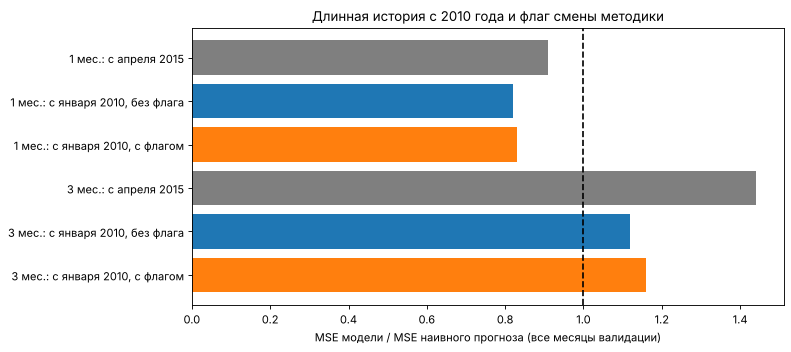

In [5]:
features = ["d_gas_europe", "d_dap", "d_coal_aus", "d_aluminum", "d_brent", "d_gas_us", "d_copper"]
flag_features = features + ["gas_oil_indexed", "d_gas_x_flag"]

def ridge_on(columns):
    # модель Ridge на заданных признаках; цель: изменение цены в логарифмах через h месяцев
    def fit_predict(known, now):
        model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
        model.fit(known[columns], np.log(known["y"] / known["price"]))
        return now["price"].iloc[0] * np.exp(model.predict(now[columns])[0])
    return fit_predict

rows = []
for h in [1, 3]:
    table = make_table_full(prices, h)
    table["gas_oil_indexed"] = (table.index < BREAK).astype(int)
    table["d_gas_x_flag"] = table["d_gas_europe"] * table["gas_oil_indexed"]
    table = table[["price", "gas", "y"] + flag_features]
    origins = table.loc["2020-10":"2023-09"].index
    origins = origins[origins <= pd.Timestamp("2023-09-01") - pd.DateOffset(months=h)]
    for name, data, columns in [("с апреля 2015", table.loc["2015-04":], features),
                                ("с января 2010, без флага", table, features),
                                ("с января 2010, с флагом", table, flag_features)]:
        res = score(rolling_backtest(data, h, ridge_on(columns), origins))
        row = {"горизонт, мес.": h, "обучение": name}
        for part in res.index:
            row[part] = res.loc[part, "MSE модель / наивный"]
        rows.append(row)
result = pd.DataFrame(rows)
print("Отношение MSE модели к MSE наивного прогноза (меньше 1: модель лучше):")
print(result.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 4.5))
labels = [f"{r['горизонт, мес.']} мес.: {r['обучение']}" for _, r in result.iterrows()]
ax.barh(labels, result["все"], color=["tab:gray", "tab:blue", "tab:orange"] * 2)
ax.axvline(1, color="black", linestyle="--")
ax.invert_yaxis()
ax.set_xlabel("MSE модели / MSE наивного прогноза (все месяцы валидации)")
ax.set_title("Длинная история с 2010 года и флаг смены методики")
plt.tight_layout()
plt.show()

**Главный результат: обучение на данных с 2010 года делает прогноз точнее, а флаг смены методики для прогноза не нужен.**

- На горизонте в один месяц ошибка модели падает с 0,91 до 0,82 от ошибки наивного прогноза. Вне кризиса выигрыш особенно заметен: отношение падает с 0,74 до 0,53.
- На горизонте в три месяца модель, обученная с 2015 года, проигрывает наивному прогнозу (1,44), а модель, обученная с 2010 года, проигрывает заметно меньше (1,12). Вне кризиса она выигрывает (0,68).
- Флаг смены методики и признак «изменение цены газа × флаг» результат не улучшают (0,83 против 0,82 и 1,16 против 1,12). Причина в том, что до 2015 года изменение цены газа почти не менялось и мало влияло на прогноз, поэтому модели нечего различать.
- Длинная история помогает, скорее всего, за счёт остальных признаков (удобрения, уголь, нефть, металлы), у которых методика не менялась: у модели становится в полтора раза больше примеров для обучения.

**Оговорка.** Набор из 7 признаков отобран в основном ноутбуке на трейне с 2015 года, который включает месяцы этой валидации. Поэтому абсолютные значения ошибок могут быть немного оптимистичными. Сравнение вариантов между собой при этом честное, потому что во всех вариантах используются одни и те же признаки.

## 5. Итог: как продлить данные до 2010 года и что предложить куратору

**Главный результат: данные можно продлить до 2010 года. Для прогноза изменения цены это даже полезно, а смену методики цены газа нужно учитывать только в разложении цены на газовую составляющую и надбавку.**

1. **Прогноз изменения цены карбамида.** Обучаем модель на данных с января 2010 года. Целевая переменная не зависит от k, поэтому смена методики газа её не портит, а дополнительные 63 месяца уменьшают ошибку прогноза. Флаг gas_oil_indexed оставляем в данных для прозрачности, но в модель он ничего не добавляет.
2. **Разложение цены на газовую составляющую и надбавку.** Оставляем период с апреля 2015 года. До 2015 года в колонке газа Европы стоит другой показатель, k по нему оценивается очень неточно (около 28 ± 11), а тест Чоу подтверждает сдвиг связи в уровнях в апреле 2015 года.
3. **Проверка устойчивости.** Надбавка с k = 12 остаётся стационарной и на длинной выборке с 2010 года (t = −4,15), поэтому выбор k = 12 не зависит от того, с какого года начинать.
4. **Другие смены методики.** Смена котировки карбамида в марте 2022 года (флаг fob_me) и смена котировки калия в январе 2020 года на период с 2010 года не влияют дополнительно и учитываются так же, как в основном ноутбуке.
5. **Как убрать проблему полностью.** Настоящая история цен TTF до 2015 года есть в платных источниках (ICE Endex, Bloomberg, Argus). Если у ВШЭ есть доступ к терминалу Bloomberg, можно заменить цену на границе настоящим TTF, и смена методики исчезнет.